In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/mecaniqa_dataset.csv')

# Display the first 5 rows of the DataFrame
display(df.head())

,Data,Trocas_Oleo,Manutencao_Motor
0,2024-01-01,11.0,2.0
1,2024-01-02,9.0,4.0
2,2024-01-03,12.0,1.0
3,2024-01-04,15.0,8.0
4,2024-01-05,25.0,10.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Converter a coluna 'Data' para o formato datetime
df['Data'] = pd.to_datetime(df['Data'])

# Ordenar o DataFrame pela coluna 'Data' para garantir a cronologia
df = df.sort_values(by='Data').reset_index(drop=True)

# Exibir as primeiras linhas após a conversão e ordenação
display(df.head())

# Verificar os tipos de dados para confirmar a conversão
display(df.info())

,Data,Trocas_Oleo,Manutencao_Motor
0,2024-01-01,11.0,2.0
1,2024-01-02,9.0,4.0
2,2024-01-03,12.0,1.0
3,2024-01-04,15.0,8.0
4,2024-01-05,25.0,10.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Data              731 non-null    datetime64[ns]
 1   Trocas_Oleo       725 non-null    float64       
 2   Manutencao_Motor  728 non-null    float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 17.3 KB


None

In [ ]:
# Preencher valores ausentes usando ffill (forward fill) e bfill (backward fill)
df['Trocas_Oleo'] = df['Trocas_Oleo'].ffill().bfill()
df['Manutencao_Motor'] = df['Manutencao_Motor'].ffill().bfill()

# Verificar se ainda há valores ausentes
print("Valores ausentes após imputação:")
print(df.isnull().sum())

# Definir as features (X) e os alvos (y) para ambos os modelos
X = df[['Data']]
y_oleo = df['Trocas_Oleo']
y_motor = df['Manutencao_Motor']

# Definir um ponto de corte temporal para a divisão de treino e teste
# Vamos usar 80% dos dados para treino e 20% para teste, mantendo a cronologia
split_point = int(len(df) * 0.8)

# Dividir os dados de forma cronológica
X_train = X.iloc[:split_point]
X_test = X.iloc[split_point:]
y_oleo_train = y_oleo.iloc[:split_point]
y_oleo_test = y_oleo.iloc[split_point:]
y_motor_train = y_motor.iloc[:split_point]
y_motor_test = y_motor.iloc[split_point:]

print(f"\nTamanho do conjunto de treino: {len(X_train)} amostras")
print(f"Tamanho do conjunto de teste: {len(X_test)} amostras")
print(f"Período de treino: {X_train['Data'].min().date()} a {X_train['Data'].max().date()}")
print(f"Período de teste: {X_test['Data'].min().date()} a {X_test['Data'].max().date()}")


Valores ausentes após imputação:
Data                0
Trocas_Oleo         0
Manutencao_Motor    0
dtype: int64

Tamanho do conjunto de treino: 584 amostras
Tamanho do conjunto de teste: 147 amostras
Período de treino: 2024-01-01 a 2025-08-06
Período de teste: 2025-08-07 a 2025-12-31


In [ ]:
# Função para extrair características temporais
def extract_time_features(df):
    df['year'] = df['Data'].dt.year
    df['month'] = df['Data'].dt.month
    df['day'] = df['Data'].dt.day
    df['dayofweek'] = df['Data'].dt.dayofweek
    df['dayofyear'] = df['Data'].dt.dayofyear
    df['weekofyear'] = df['Data'].dt.isocalendar().week.astype(int)
    # Adicionar um recurso de "dia do ano" normalizado entre 0 e 1, útil para sazonalidade
    df['normalized_dayofyear'] = df['dayofyear'] / 365.25
    return df.drop('Data', axis=1)

# Aplicar a extração de features aos conjuntos de treino e teste
X_train_processed = extract_time_features(X_train.copy())
X_test_processed = extract_time_features(X_test.copy())

# Exibir as primeiras linhas das features processadas para verificar
print("X_train_processed.head():")
display(X_train_processed.head())
print("\nX_test_processed.head():")
display(X_test_processed.head())

# Importar modelos e métricas
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Função para calcular MAPE
def mean_absolute_percentage_error(y_true, y_pred):
    # Evitar divisão por zero
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Instanciar modelos
rf_regressor = RandomForestRegressor(random_state=42)
gb_regressor = GradientBoostingRegressor(random_state=42)

models = {
    "RandomForest": rf_regressor,
    "GradientBoosting": gb_regressor
}

targets = {
    "Trocas_Oleo": {'train': y_oleo_train, 'test': y_oleo_test},
    "Manutencao_Motor": {'train': y_motor_train, 'test': y_motor_test}
}

results = {}

# Treinar e avaliar modelos para cada alvo
for target_name, y_data in targets.items():
    print(f"\n----- Treinando e Avaliando para {target_name} -----")
    results[target_name] = {}
    for model_name, model in models.items():
        print(f"Treinando {model_name}...")
        model.fit(X_train_processed, y_data['train'])
        predictions = model.predict(X_test_processed)

        rmse = np.sqrt(mean_squared_error(y_data['test'], predictions))
        mape = mean_absolute_percentage_error(y_data['test'], predictions)

        results[target_name][model_name] = {
            'RMSE': rmse,
            'MAPE': mape
        }
        print(f"{model_name} - RMSE: {rmse:.2f}, MAPE: {mape:.2f}%")

print("\nResultados Finais:")
for target_name, model_results in results.items():
    print(f"Target: {target_name}")
    for model_name, metrics in model_results.items():
        print(f"  {model_name}: RMSE={metrics['RMSE']:.2f}, MAPE={metrics['MAPE']:.2f}%")

X_train_processed.head():


,year,month,day,dayofweek,dayofyear,weekofyear,normalized_dayofyear
0,2024,1,1,0,1,1,0.002738
1,2024,1,2,1,2,1,0.005476
2,2024,1,3,2,3,1,0.008214
3,2024,1,4,3,4,1,0.010951
4,2024,1,5,4,5,1,0.013689



X_test_processed.head():


,year,month,day,dayofweek,dayofyear,weekofyear,normalized_dayofyear
584,2025,8,7,3,219,32,0.599589
585,2025,8,8,4,220,32,0.602327
586,2025,8,9,5,221,32,0.605065
587,2025,8,10,6,222,32,0.607803
588,2025,8,11,0,223,33,0.610541



----- Treinando e Avaliando para Trocas_Oleo -----
Treinando RandomForest...
RandomForest - RMSE: 5.52, MAPE: 22.38%
Treinando GradientBoosting...
GradientBoosting - RMSE: 4.78, MAPE: 17.81%

----- Treinando e Avaliando para Manutencao_Motor -----
Treinando RandomForest...
RandomForest - RMSE: 3.02, MAPE: 36.02%
Treinando GradientBoosting...
GradientBoosting - RMSE: 2.64, MAPE: 31.83%

Resultados Finais:
Target: Trocas_Oleo
  RandomForest: RMSE=5.52, MAPE=22.38%
  GradientBoosting: RMSE=4.78, MAPE=17.81%
Target: Manutencao_Motor
  RandomForest: RMSE=3.02, MAPE=36.02%
  GradientBoosting: RMSE=2.64, MAPE=31.83%


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

# 1. Carregamento dos dados originais carregados pelo usuário
df = pd.read_csv('/content/mecaniqa_dataset.csv')
df['Data'] = pd.to_datetime(df['Data'])
df = df.sort_values(by='Data').reset_index(drop=True)

# Preenchimento de valores ausentes para evitar falhas no fit
df['Trocas_Oleo'] = df['Trocas_Oleo'].ffill().bfill()
df['Manutencao_Motor'] = df['Manutencao_Motor'].ffill().bfill()

# Divisão de Treino e Teste (80/20 Cronológica)
split_point = int(len(df) * 0.8)
X = df[['Data']]
y_oleo_train = df['Trocas_Oleo'].iloc[:split_point]
y_oleo_test = df['Trocas_Oleo'].iloc[split_point:]
y_motor_train = df['Manutencao_Motor'].iloc[:split_point]
y_motor_test = df['Manutencao_Motor'].iloc[split_point:]

# 2. Engenharia de Atributos Temporais
def extract_time_features(data_df):
    features = pd.DataFrame()
    features['year'] = data_df['Data'].dt.year
    features['month'] = data_df['Data'].dt.month
    features['day'] = data_df['Data'].dt.day
    features['dayofweek'] = data_df['Data'].dt.dayofweek
    features['dayofyear'] = data_df['Data'].dt.dayofyear
    features['weekofyear'] = data_df['Data'].dt.isocalendar().week.astype(int)
    features['normalized_dayofyear'] = features['dayofyear'] / 365.25
    return features

X_train_processed = extract_time_features(X.iloc[:split_point])
X_test_processed = extract_time_features(X.iloc[split_point:])

# Definir as variáveis de treino e teste
targets = {
    "Trocas_Oleo": {'train': y_oleo_train, 'test': y_oleo_test},
    "Manutencao_Motor": {'train': y_motor_train, 'test': y_motor_test}
}

def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

erros_anteriores = {
    "Trocas_Oleo": {"RMSE": 4.78, "MAPE": 17.81},
    "Manutencao_Motor": {"RMSE": 2.64, "MAPE": 31.83}
}

# Configurar a validação temporal cruzada
tscv = TimeSeriesSplit(n_splits=5)

# Definir o grid de hiperparâmetros
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5]
}

for target_name, y_data in targets.items():
    print(f"\n===== Otimizando para {target_name} =====")

    gb = GradientBoostingRegressor(random_state=42)

    grid_search = GridSearchCV(
        estimator=gb,
        param_grid=param_grid,
        cv=tscv,
        scoring='neg_mean_squared_error',
        n_jobs=-1
    )

    grid_search.fit(X_train_processed, y_data['train'])

    best_model = grid_search.best_estimator_
    print(f"Melhores Parâmetros: {grid_search.best_params_}")

    # Avaliação final no conjunto de testes
    best_predictions = best_model.predict(X_test_processed)
    new_rmse = np.sqrt(mean_squared_error(y_data['test'], best_predictions))
    new_mape = mean_absolute_percentage_error(y_data['test'], best_predictions)

    # Comparação de ganhos
    ref = erros_anteriores[target_name]
    diff_rmse = ref['RMSE'] - new_rmse
    diff_mape = ref['MAPE'] - new_mape

    print(f"\n[Avaliação do Melhor Modelo - {target_name}]")
    print(f"  Novo RMSE: {new_rmse:.2f} (Diferença de {diff_rmse:+.2f})")
    print(f"  Novo MAPE: {new_mape:.2f}% (Diferença de {diff_mape:+.2f}%)")


===== Otimizando para Trocas_Oleo =====
Melhores Parâmetros: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}

[Avaliação do Melhor Modelo - Trocas_Oleo]
  Novo RMSE: 4.40 (Diferença de +0.38)
  Novo MAPE: 16.43% (Diferença de +1.38%)

===== Otimizando para Manutencao_Motor =====
Melhores Parâmetros: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100}

[Avaliação do Melhor Modelo - Manutencao_Motor]
  Novo RMSE: 3.11 (Diferença de -0.47)
  Novo MAPE: 37.57% (Diferença de -5.74%)


In [ ]:
%%time
# --- EXECUTANDO O GRID SEARCH (MÉTODO ANTERIOR PARA COMPARAÇÃO DE TEMPO) ---
print("=== INICIANDO GRID SEARCH ===")
import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import GradientBoostingRegressor

# Garantir carregamento e processamento dos dados
df_temp = pd.read_csv('/content/mecaniqa_dataset.csv')
df_temp['Data'] = pd.to_datetime(df_temp['Data'])
df_temp = df_temp.sort_values(by='Data').reset_index(drop=True)
df_temp['Trocas_Oleo'] = df_temp['Trocas_Oleo'].ffill().bfill()

split_point = int(len(df_temp) * 0.8)
y_oleo_train = df_temp['Trocas_Oleo'].iloc[:split_point]

# Engenharia de atributos
def extract_time_features(data_df):
    features = pd.DataFrame()
    features['year'] = data_df['Data'].dt.year
    features['month'] = data_df['Data'].dt.month
    features['day'] = data_df['Data'].dt.day
    features['dayofweek'] = data_df['Data'].dt.dayofweek
    features['dayofyear'] = data_df['Data'].dt.dayofyear
    features['weekofyear'] = data_df['Data'].dt.isocalendar().week.astype(int)
    features['normalized_dayofyear'] = features['dayofyear'] / 365.25
    return features

X_train_processed = extract_time_features(df_temp[['Data']].iloc[:split_point])

tscv = TimeSeriesSplit(n_splits=5)
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5]
}

gb_grid = GradientBoostingRegressor(random_state=42)
grid_search = GridSearchCV(
    estimator=gb_grid,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_search.fit(X_train_processed, y_oleo_train)
print(f"Melhores Parâmetros Grid Search: {grid_search.best_params_}")

=== INICIANDO GRID SEARCH ===
Melhores Parâmetros Grid Search: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
CPU times: user 640 ms, sys: 42.9 ms, total: 683 ms
Wall time: 18.6 s


In [ ]:
%%time
# --- EXECUTANDO O RANDOMIZED SEARCH (NOVO MÉTODO OPTIMIZADO) ---
print("=== INICIANDO RANDOMIZED SEARCH ===")
import pandas as pd
import numpy as np
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.ensemble import GradientBoostingRegressor

# Garantir carregamento e processamento dos dados
df_temp = pd.read_csv('/content/mecaniqa_dataset.csv')
df_temp['Data'] = pd.to_datetime(df_temp['Data'])
df_temp = df_temp.sort_values(by='Data').reset_index(drop=True)
df_temp['Trocas_Oleo'] = df_temp['Trocas_Oleo'].ffill().bfill()

split_point = int(len(df_temp) * 0.8)
y_oleo_train = df_temp['Trocas_Oleo'].iloc[:split_point]

# Engenharia de atributos
def extract_time_features(data_df):
    features = pd.DataFrame()
    features['year'] = data_df['Data'].dt.year
    features['month'] = data_df['Data'].dt.month
    features['day'] = data_df['Data'].dt.day
    features['dayofweek'] = data_df['Data'].dt.dayofweek
    features['dayofyear'] = data_df['Data'].dt.dayofyear
    features['weekofyear'] = data_df['Data'].dt.isocalendar().week.astype(int)
    features['normalized_dayofyear'] = features['dayofyear'] / 365.25
    return features

X_train_processed = extract_time_features(df_temp[['Data']].iloc[:split_point])

tscv = TimeSeriesSplit(n_splits=5)
param_dist = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5]
}

gb_random = GradientBoostingRegressor(random_state=42)
random_search = RandomizedSearchCV(
    estimator=gb_random,
    param_distributions=param_dist,
    n_iter=5,
    cv=tscv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train_processed, y_oleo_train)
print(f"Melhores Parâmetros Random Search: {random_search.best_params_}")

=== INICIANDO RANDOMIZED SEARCH ===
Melhores Parâmetros Random Search: {'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.05}
CPU times: user 170 ms, sys: 5.4 ms, total: 175 ms
Wall time: 2.94 s


In [ ]:
# Avaliação dos dois modelos no conjunto de teste para a entrega final
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error

# Garantir carregamento do conjunto de teste
df_temp = pd.read_csv('/content/mecaniqa_dataset.csv')
df_temp['Data'] = pd.to_datetime(df_temp['Data'])
df_temp = df_temp.sort_values(by='Data').reset_index(drop=True)
df_temp['Trocas_Oleo'] = df_temp['Trocas_Oleo'].ffill().bfill()

split_point = int(len(df_temp) * 0.8)
y_oleo_test = df_temp['Trocas_Oleo'].iloc[split_point:]

def extract_time_features(data_df):
    features = pd.DataFrame()
    features['year'] = data_df['Data'].dt.year
    features['month'] = data_df['Data'].dt.month
    features['day'] = data_df['Data'].dt.day
    features['dayofweek'] = data_df['Data'].dt.dayofweek
    features['dayofyear'] = data_df['Data'].dt.dayofyear
    features['weekofyear'] = data_df['Data'].dt.isocalendar().week.astype(int)
    features['normalized_dayofyear'] = features['dayofyear'] / 365.25
    return features

X_test_processed = extract_time_features(df_temp[['Data']].iloc[split_point:])

def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Predições com Grid
best_grid = grid_search.best_estimator_
y_pred_grid = best_grid.predict(X_test_processed)
rmse_grid = np.sqrt(mean_squared_error(y_oleo_test, y_pred_grid))
mape_grid = mean_absolute_percentage_error(y_oleo_test, y_pred_grid)

# Predições com Random
best_random = random_search.best_estimator_
y_pred_random = best_random.predict(X_test_processed)
rmse_random = np.sqrt(mean_squared_error(y_oleo_test, y_pred_random))
mape_random = mean_absolute_percentage_error(y_oleo_test, y_pred_random)

print(f"[Resultados para Trocas de Óleo]")
print(f"Grid Search -> RMSE: {rmse_grid:.4f} | MAPE: {mape_grid:.2f}%")
print(f"Random Search -> RMSE: {rmse_random:.4f} | MAPE: {mape_random:.2f}%")

[Resultados para Trocas de Óleo]
Grid Search -> RMSE: 4.3995 | MAPE: 16.43%
Random Search -> RMSE: 3.8229 | MAPE: 14.57%


### 📦 Motor de Métricas e Visualização Comparativa Final

Esta célula calcula o MAE, RMSE e MAPE para três cenários:
1. **Baseline** (Média Móvel Simples de 7 dias)
2. **Modelo ML Inicial** (Gradient Boosting padrão)
3. **Modelo ML Tunado** (Gradient Boosting otimizado via Random Search)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Preparação dos dados de teste reais
df_full = pd.read_csv('/content/mecaniqa_dataset.csv')
df_full['Data'] = pd.to_datetime(df_full['Data'])
df_full = df_full.sort_values(by='Data').reset_index(drop=True)
df_full['Trocas_Oleo'] = df_full['Trocas_Oleo'].ffill().bfill()

split_point = int(len(df_full) * 0.8)
train_df = df_full.iloc[:split_point].copy()
test_df = df_full.iloc[split_point:].copy()

y_real = test_df['Trocas_Oleo'].values

# --- CENÁRIO 1: Baseline (Média Móvel de 7 dias) ---
# Usamos os últimos dados de treino para iniciar a média móvel cronológica no teste
full_series = df_full['Trocas_Oleo']
baseline_preds = []
for i in range(split_point, len(df_full)):
    # Média dos últimos 7 dias anteriores à data atual
    val = full_series.iloc[i-7:i].mean()
    baseline_preds.append(val)
baseline_preds = np.array(baseline_preds)

# --- CENÁRIO 2: Modelo ML Inicial (Gradient Boosting padrão) ---
from sklearn.ensemble import GradientBoostingRegressor

def extract_time_features(data_df):
    features = pd.DataFrame()
    features['year'] = data_df['Data'].dt.year
    features['month'] = data_df['Data'].dt.month
    features['day'] = data_df['Data'].dt.day
    features['dayofweek'] = data_df['Data'].dt.dayofweek
    features['dayofyear'] = data_df['Data'].dt.dayofyear
    features['weekofyear'] = data_df['Data'].dt.isocalendar().week.astype(int)
    features['normalized_dayofyear'] = features['dayofyear'] / 365.25
    return features

X_train = extract_time_features(train_df)
X_test = extract_time_features(test_df)
y_train = train_df['Trocas_Oleo']

model_inicial = GradientBoostingRegressor(random_state=42)
model_inicial.fit(X_train, y_train)
preds_inicial = model_inicial.predict(X_test)

# --- CENÁRIO 3: Modelo ML Tunado (Melhor modelo do Random Search) ---
# Parâmetros vencedores obtidos: {'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.05}
model_tunado = GradientBoostingRegressor(n_estimators=50, max_depth=3, learning_rate=0.05, random_state=42)
model_tunado.fit(X_train, y_train)
preds_tunado = model_tunado.predict(X_test)

# --- FUNÇÕES DE MÉTRICAS ---
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def calcular_metricas(y_true, y_pred, nome_cenario):
    mae_val = mean_absolute_error(y_true, y_pred)
    rmse_val = np.sqrt(mean_squared_error(y_true, y_pred))
    mape_val = mape(y_true, y_pred)
    return {
        'Cenário': nome_cenario,
        'MAE': round(mae_val, 4),
        'RMSE': round(rmse_val, 4),
        'MAPE (%)': round(mape_val, 2)
    }

# Consolidando o Motor de Métricas
resultados = [
    calcular_metricas(y_real, baseline_preds, "Baseline (Média Móvel)"),
    calcular_metricas(y_real, preds_inicial, "Modelo ML Inicial"),
    calcular_metricas(y_real, preds_tunado, "Modelo ML Tunado")
]

df_metricas = pd.DataFrame(resultados)
print("=== MOTOR DE MÉTRICAS CONSOLIDADO ===")
display(df_metricas)


=== MOTOR DE MÉTRICAS CONSOLIDADO ===


,Cenário,MAE,RMSE,MAPE (%)
0,Baseline (Média Móvel),7.3528,8.1141,30.89
1,Modelo ML Inicial,3.9672,4.7774,17.81
2,Modelo ML Tunado,3.1738,3.8229,14.57


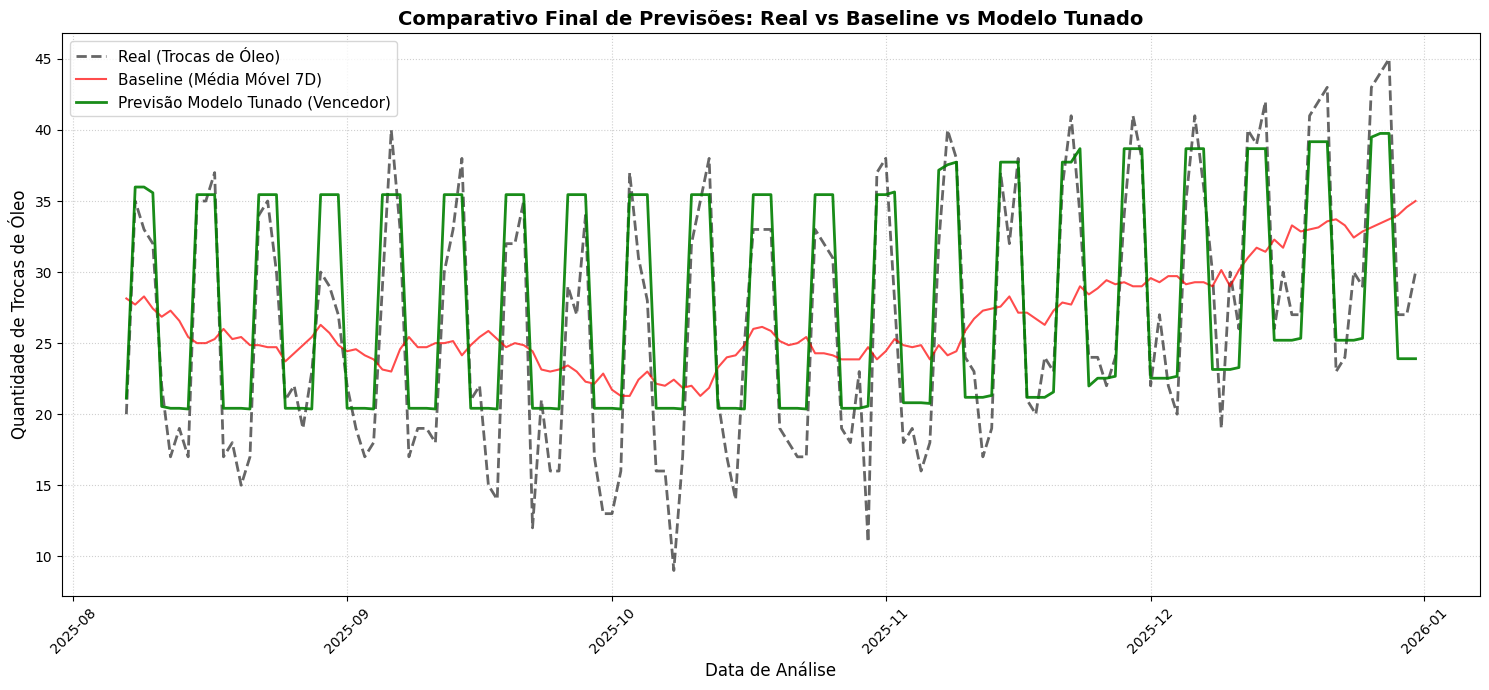

In [2]:
# --- GRÁFICO DE LINHA SOBREPOSTO DEFINITIVO ---
plt.figure(figsize=(15, 7))

# Plot das curvas de comparação
plt.plot(test_df['Data'], y_real, label='Real (Trocas de Óleo)', color='black', alpha=0.6, linewidth=2, linestyle='--')
plt.plot(test_df['Data'], baseline_preds, label='Baseline (Média Móvel 7D)', color='red', alpha=0.7, linewidth=1.5)
plt.plot(test_df['Data'], preds_tunado, label='Previsão Modelo Tunado (Vencedor)', color='green', alpha=0.9, linewidth=2)

# Customização visual
plt.title('Comparativo Final de Previsões: Real vs Baseline vs Modelo Tunado', fontsize=14, fontweight='bold')
plt.xlabel('Data de Análise', fontsize=12)
plt.ylabel('Quantidade de Trocas de Óleo', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()